# HW4 -- MAKE A COPY BEFORE YOU BEGIN

In [ ]:
!pip install --upgrade "git+https://github.com/RyanMarcus/penngrader2.git@8a34a2c"

# Setup

Change the `penngrader2.login` call below to your student ID. Do not change anything else in the below cell.

In [ ]:
import penngrader2
import numpy as np

penngrader2.configure("https://pg2.rmarcus.info/", api_key="de61f526fe91fa3327ba4c61041f6bf68a669ff3b3d881747ed66984f1cabbdd")
penngrader2.login(10855639)


# Part 1: Alzheimer's Prediction Dataset

We're going to test various machine learning models to detect dementia induced by Alzheimer's. Our models will take brain MRIs as input, and predict the level of dementia.

We'll begin by downloading, organizing, and exploring our data. While we do, we'll learn about [Apache Parquet](https://parquet.apache.org/) and [pyarrow](https://pypi.org/project/pyarrow/), a set of tools for working with large datasets.

## 1.1: Download and view image data (5 points)

First, we download the dataset from the web:

In [ ]:
!apt install zstd
!wget -nc https://upenn.ferric.systems/cis5450/alzheimers.tar.zst
!tar --zstd -xvf alzheimers.tar.zst

Each file is a JPG image stored in `/content/alzheimers/`. Images are under one of four subfolders:

* `NonDemented`: no signs of dementia
* `VeryMildDemented`: early signs of dementia
* `MildDemented`: signs of dementia
* `ModerateDemented`: signs of strong dementia

As a first step, let's look at a few examples from each folder. Using `matplotlib`, create a photo array with 4 columns (one for each class) and three rows (for each sample image), displaying 12 sample images. Label each image with it's class. Make sure to remove the axes. Save the image as `panel.jpg`.

You can read and plot image data from a JPG like this:

```
data = Image.open("/path/to/image.jpg")
plt.imshow(data, cmap="gray")
```

In [ ]:
from matplotlib import pyplot as plt
import os
import random
from PIL import Image

In [ ]:
random.seed(0)
classes = ["NonDemented", "VeryMildDemented", "MildDemented", "ModerateDemented"]
fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for c, cls in enumerate(classes):
    files = random.sample(sorted(os.listdir(f"/content/alzheimers/{cls}")), 3)
    for r, f in enumerate(files):
        ax = axes[r, c]
        ax.imshow(Image.open(f"/content/alzheimers/{cls}/{f}"), cmap="gray")
        ax.set_title(cls, fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.savefig("panel.jpg")

In [ ]:
import base64
with open("panel.jpg", "rb") as f:
  imgdata = base64.b64encode(f.read()).decode("utf-8")
penngrader2.submit("hw4", "problem1_1", imgdata)

## 1.2: Creating a Parquet file

Currently, our data is stored as individual image files in directories with our class labels. This is fine, but is not very consistent. It is easy to lose a file, or perhaps even an entire class, from the dataset.

Next, we'll build a [Parquet](https://parquet.apache.org) file containing all of our data. Parquet is a columnar format, meaning each column is stored independently. This means we can quickly access arbitrary slices of the data.

Storing images in a Parquet file might seem unusual. While Parquet was mostly designed for tabular data, for small image files (like ours), creating a Parquet file allows us to store and transmit a single file easily. For datasets with significantly larger images, it might make more sense to include a URL to the image in the Parquet file instead of the image itself.

We'll create a Parquet file naned `mri.parquet` with four columns:

* `img_path`, a string column containing the original image path in our dataset, such as `alzheimers/MildDemented/00046ff7-0fae-4796-9a2b-2df47095bfe6.jpg`
* `img_class`, a string column containing the image's class (e.g., `MildDemented`).
* `img_class_numeric`, an 8-bit unsigned integer column reprsenting the class (0 for `NonDemented`, 3 for `ModerateDemented`).
* `img_data`, a binary column containing the raw image data.

You can read image data like this:

```python
with open("path/to/image.jpg", "rb") as f:
  img_data = f.read()
```

It is important that we do not load every single image into memory before dumping them into a Parquet file. While this dataset could potentially fit in our Colab machine's memory, we do not want to make that assumption. Therefore, we want to read a small batch of images, write them to the Parquet file, then go to the next batch. We'll use a batch size of 64.

You can write a Parquet file incrementally like this:

```python
import pyarrow.parquet as pq
with pq.ParquetWriter('mri.parquet', schema) as writer:
  writer.write(table)
```

You'll need to lookup how to construct a PyArrow `table`.


In [ ]:
import os
import pyarrow.parquet as pq
import pyarrow as pa

classes = ["NonDemented", "VeryMildDemented", "MildDemented", "ModerateDemented"]
schema = pa.schema([
    pa.field("img_path", pa.string()),
    pa.field("img_class", pa.string()),
    pa.field("img_class_numeric", pa.uint8()),
    pa.field("img_data", pa.binary()),
])

# only metadata is collected up front; image bytes are read one batch at a time
items = []
for idx, cls in enumerate(classes):
    for f in sorted(os.listdir(f"alzheimers/{cls}")):
        items.append((f"alzheimers/{cls}/{f}", cls, idx))

BATCH = 64
with pq.ParquetWriter("mri.parquet", schema) as writer:
    for i in range(0, len(items), BATCH):
        batch = items[i:i + BATCH]
        datas = []
        for p, _, _ in batch:
            with open(p, "rb") as f:
                datas.append(f.read())
        table = pa.table({
            "img_path": [b[0] for b in batch],
            "img_class": [b[1] for b in batch],
            "img_class_numeric": pa.array([b[2] for b in batch], type=pa.uint8()),
            "img_data": pa.array(datas, type=pa.binary()),
        }, schema=schema)
        writer.write_table(table)

In [ ]:
# WARNING: YOU MUST RUN THIS CELL IMMEDIATELY AFTER RUNNING THE CELL ABOVE. If
# you run some cell in between, you will get a nonsense grade.

src = In[len(In) - 2]

df = pq.read_table("mri.parquet", columns=["img_class", "img_class_numeric"]).to_pandas()
icc = df["img_class"].value_counts().to_json()
icnc = df["img_class_numeric"].value_counts().to_json()
penngrader2.submit("hw4", "problem1_2", {"src": src, "icc": icc, "icnc": icnc})

## 1.3: Class counts with Parquet (5 points)

Let's figure out how many of each class we have in our dataset. To do this, we'll use DuckDB to query our Parquet file. Modify the `query` variable below to compute the number of times each class occurs, sorted by the most frequent class first.

In [ ]:
import duckdb
query = """
select img_class, count(*) as count
from read_parquet('mri.parquet')
group by img_class
order by count desc;
"""

counts = duckdb.sql(query)
counts

In [ ]:
penngrader2.submit("hw4", "problem1_3", query)

## 1.4: Normalizing images

Our MRI images come in a variety of dimensions. Some are 180x200, others are 140x180. In order to treat each image as the same type, we have to normalize them so that they are all the same size. We can do this by taking a 120x120 center crop of each image.

Scientific images can also have *bias*, meaning that some images may be brighter or duller than others. We can compensate for this by normalizing the minimum and maximum brightness value in each image.

We'll develop our image normalization pipeline first, then we'll apply it on top of our Parquet file.

array([[51, 51, 51, ..., 51, 51, 51],
       [51, 51, 51, ..., 51, 51, 51],
       [51, 51, 51, ..., 51, 51, 51],
       ...,
       [51, 51, 51, ..., 51, 51, 51],
       [51, 51, 51, ..., 51, 51, 51],
       [51, 51, 51, ..., 51, 51, 51]], dtype=uint8)
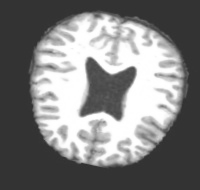

In [ ]:
import io

# load some sample images into memory
images = pq.read_table("mri.parquet", columns=["img_data"])["img_data"].chunks[0]
images = [Image.open(io.BytesIO(r.as_buffer())).convert("L") for r in images]
images = [np.array(x) for x in images]
images[0]

In [ ]:
# crop the stack of image array to exactly 120x120 in the center
def crop_center(img):
    h, w = img.shape[:2]
    top, left = (h - 120) // 2, (w - 120) // 2
    return img[top:top + 120, left:left + 120]

crop_center(images[0])

In [ ]:
# normalize the image so that the lowest value is 0 and the largest value is 255
# make sure your numpy dtype ends up being uint8 at the end!
def normalize(img):
  img = img.astype(np.float32)
  lo, hi = img.min(), img.max()
  if hi == lo:
    return np.zeros(img.shape, dtype=np.uint8)
  return ((img - lo) / (hi - lo) * 255).round().astype(np.uint8)

normalize(crop_center(images[0]))

In [ ]:

# PennGrader
img = Image.open("/content/alzheimers/MildDemented/00046ff7-0fae-4796-9a2b-2df47095bfe6.jpg").convert("L")
img = np.array(img)
img = normalize(crop_center(img))
img = img.flatten().tolist()
penngrader2.submit("hw4", "problem1_4", img)


## 1.5 Writing the cleaned data

Next, we'll construct a new Parquet file with our cleaned up images. Instead of storing the JPG binary data, we'll store the 120*120 = 14400 brightness values as a fixed size list.

To do this transformation reasonably, you must write out the new Parquet *while you are reading the current one*! Call the new Parquet file `cleaned_mri.parquet`.

In [ ]:
img_array_type = pa.list_(pa.uint8(), list_size=14400)
schema = pa.schema([
    pa.field("img_path", pa.string()),
    pa.field("img_class", pa.string()),
    pa.field("img_class_numeric", pa.uint8()),
    pa.field("img_data", pa.binary()),
    pa.field("img_array", img_array_type)
])

pf = pq.ParquetFile("mri.parquet")

with pq.ParquetWriter("cleaned_mri.parquet", schema) as writer:
    for batch in pf.iter_batches(batch_size=64):
        raw = batch["img_data"].to_pylist()
        arr = np.stack([
            normalize(crop_center(np.array(Image.open(io.BytesIO(b)).convert("L")))).ravel()
            for b in raw
        ])
        img_array = pa.FixedSizeListArray.from_arrays(pa.array(arr.ravel(), type=pa.uint8()), 14400)
        table = pa.table({
            "img_path": batch["img_path"],
            "img_class": batch["img_class"],
            "img_class_numeric": batch["img_class_numeric"],
            "img_data": batch["img_data"],
            "img_array": img_array,
        }, schema=schema)
        writer.write_table(table)

In [ ]:
df = pq.read_table("cleaned_mri.parquet", columns=["img_class", "img_class_numeric"]).to_pandas()
icc = df["img_class"].value_counts().to_json()
icnc = df["img_class_numeric"].value_counts().to_json()
penngrader2.submit("hw4", "problem1_5", {"icc": icc, "icnc": icnc})

# Part 2: Image analysis and feature extraction

Now that we have our image dataset created, let's analyze our images a bit and extract features from them. Then, we'll use those extracted features to build a classifier.

Later, we'll use convolutional neural networks to automatically engineer features for us.

# 2.1: Incremental PCA over MRIs (5 points)

We'll start by applying [principal component analysis](https://scikit-learn.org/stable/modules/decomposition.html#pca) to our image data. This will help us identify the key components of dataset, such that each image can be represented as a mixture of those components.

Our dataset is too large to use the usual PCA algorithm. There's two alternative ways for us to compute PCA: incremental PCA and sampling. First, we'll use [incremental PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.IncrementalPCA.html) to handle our dataset.

Using an `IncrementalPCA` with 10 components called `pca`, use the `partial_fit` function to train on batches of 256 images at a time. Do not load the entire dataset into memory -- build these batchs in a streaming fashion from the Parquet file using the [`iter_batches`](https://arrow.apache.org/docs/python/generated/pyarrow.parquet.ParquetFile.html?utm_source=chatgpt.com#pyarrow.parquet.ParquetFile.iter_batches) function. Make sure to only read the `img_array` column.

This will take a while to run (multiple minutes). Try to avoid converting data into Python lists when possible -- `np.vstack` might be helpful.

In [ ]:
from sklearn.decomposition import IncrementalPCA

pca = IncrementalPCA(n_components=10)
pf = pq.ParquetFile("cleaned_mri.parquet")
for batch in pf.iter_batches(batch_size=256, columns=["img_array"]):
    X = np.vstack(batch["img_array"].to_numpy(zero_copy_only=False)).astype(np.float32)
    pca.partial_fit(X)

In [ ]:
penngrader2.submit("hw4", "problem2_1", {"ns": int(pca.n_samples_seen_), "cs": pca.components_.shape})

We can visualize the components we just found, which can be viewed as the components that make up each of our scans:

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(12, 6), constrained_layout=True)
axes = axes.flatten()

for idx, (ax, comp) in enumerate(zip(axes, pca.components_)):
  comp = comp.reshape(120, 120)
  ax.imshow(comp, cmap="gray")
  ax.axis("off")
  ax.set_title(f"Component {idx}")


... and we can view any particular brain scan as a mixture of these components (i.e., a linear combination of the principal components)! Below, an example brain scan ("Original") is mapped into our component space, then reconstructed. The original and reconstructed images are plotted. The printed array of coefficients can be used as a feature representation of our images!

In [ ]:
pf = pq.ParquetFile("cleaned_mri.parquet")
img = next(pf.iter_batches(batch_size=1, columns=["img_array"]))
ex_brain = img["img_array"].to_numpy(zero_copy_only=False)[0]

as_mixture = pca.transform([ex_brain])
ex_brain = ex_brain.reshape(120, 120)
print("Coefs:", as_mixture)

reconstructed = pca.inverse_transform(as_mixture)
reconstructed = reconstructed.reshape(120, 120)

fig, axes = plt.subplots(1, 2, figsize=(4, 3), constrained_layout=True)
axes[0].imshow(ex_brain, cmap="gray")
axes[0].axis("off")
axes[0].set_title("Original")
axes[1].imshow(reconstructed, cmap="gray")
axes[1].axis("off")
axes[1].set_title("Reconstructed")

# 2.2: PCA over MRI Samples (5 points)

Doing incremental PCA was kind of a pain, and was a little slow. What if we just sampled some random scans from our dataset and did regular PCA?

After using DuckDB to sample 1000 rows from the Parquet file, use regular PCA to component 10 components of the sample. Name the PCA transformer `sample_pca`.

In [ ]:
# sample 1000 scans with duckdb
query = """
select img_array from read_parquet('cleaned_mri.parquet') using sample 1000
"""
samples = duckdb.sql(query).fetchnumpy()["img_array"]
samples = np.vstack(samples)
samples.shape


In [ ]:
# use PCA to compute 10 principal components of `samples`
from sklearn.decomposition import PCA

sample_pca = PCA(n_components=10)
sample_pca.fit(samples)

In [ ]:
penngrader2.submit("hw4", "problem2_2", {"ns": int(sample_pca.n_samples_), "cs": sample_pca.components_.shape})

We can once again see our components:

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(12, 6), constrained_layout=True)
axes = axes.flatten()

for idx, (ax, comp) in enumerate(zip(axes, sample_pca.components_)):
  comp = comp.reshape(120, 120)
  ax.imshow(comp, cmap="gray")
  ax.axis("off")
  ax.set_title(f"Component {idx}")


# 2.3 Comparing the transformations (10 points)

Now we have an incremental PCA over the full dataset (`pca`) and a regular PCA computed over samples (`sample_pca`). Let's see which one is better!

A good proxy metric for how good the components are is to look at the reconstruction error across the entire dataset. Using mean squared error, compute the reconstruction error of both transformations. To do this, iterate over batches of size 1024 from the Parquet file. Print the the final loss of both transformations.

In [ ]:
from sklearn.metrics import mean_squared_error

pf = pq.ParquetFile("cleaned_mri.parquet")
pca_se = sample_se = 0.0
n_total = 0
for batch in pf.iter_batches(batch_size=1024, columns=["img_array"]):
    X = np.vstack(batch["img_array"].to_numpy(zero_copy_only=False)).astype(np.float32)
    n = X.shape[0]
    # weight by batch size so the result is the MSE over the whole dataset
    pca_se += mean_squared_error(X, pca.inverse_transform(pca.transform(X))) * n
    sample_se += mean_squared_error(X, sample_pca.inverse_transform(sample_pca.transform(X))) * n
    n_total += n
pca_err_total = pca_se / n_total
sample_pca_err_total = sample_se / n_total

print("PCA error:", pca_err_total)
print("Sample PCA error:", sample_pca_err_total)

In [ ]:
# WARNING: YOU MUST RUN THIS CELL IMMEDIATELY AFTER RUNNING THE CELL ABOVE. If
# you run some cell in between, you will get a nonsense grade.

src = In[len(In) - 2]
penngrader2.submit("hw4", "problem2_3", src)

You should see that the new techniques create nearly identical reconstruction accuracy. Sometimes, simplicity wins! Going forward, you can use either technique.

# Part 3: Training a logistic regression model

Now that we have experience featurizing images, it is time to train a logistic regression model to predict dementia status from MRI scans. To do this, we must carefully divide our data into training and testing sets, and ensure that all training -- including fitting PCA -- only happens on the training set.

## 3.1 Creating train/test split (5 points)

`scikit-learn` has a lot of helper functions for generating training / testing splits, but many of these assume that the entire dataset can fit in memory. We will be assuming that our dataset is too large to fit in memory.

Let's do a train/test split using DuckDB. Create a new table called `data` by reading the Parquet file and then adding a new, boolean column called `train` that is true 80% of the time and false otherwise (randomly).

In [ ]:
con = duckdb.connect("data.duckdb")
con.sql("""
create or replace table data as
select *, random() < 0.8 as train
from read_parquet('cleaned_mri.parquet')
""")

In [ ]:
ts = con.sql("select count(*) from data where train").fetchone()[0]
penngrader2.submit("hw4", "problem3_1", {"ts": ts})

## 3.2 Fitting PCA on the training data (5 points)

Next, let's fit PCA on our training data. Do this by sampling 1000 rows from your training set using DuckDB, then fitting a PCA transformer called `train_pca`. You should do the sampling in DuckDB -- look up a good way to do this. Keep the order of operations in mind!

In [ ]:
from sklearn.decomposition import PCA

# NOTE: the filter must run BEFORE the sample. A plain `where train using sample 1000`
# samples first and filters afterwards (only ~800 rows survive), hence the subquery.
samples = con.sql("""
select img_array from (select img_array from data where train) using sample 1000
""").fetchnumpy()["img_array"]
samples = np.vstack(samples)
train_pca = PCA(n_components=10)
train_pca.fit(samples)

In [ ]:
penngrader2.submit("hw4", "problem3_2", {"ns": int(train_pca.n_samples_), "cs": train_pca.components_.shape})

## 3.3 Materializing the training data

Now that we have our feature extractor, we can build the feature representation for each of our images. While we should still avoid reading every image into memory at once, we can assume that all image's feature representation (10 values) can fit into memory.

Using DuckDB, stream the training data into memory, collecting the feature representation of each image into an array called `train_X`, and each image's numeric label into an array called `train_y`.

Stream batches of 1024 rows from DuckDB. To do this, you can use `con.execute("...")` to get a cursor, then `cursor.fetch_record_batch(1024)` to iterate over batches.

Once `train_X` and `train_y` have been created, use a `StandardScaler` to standardize your data input features (this is expected by scikit learn's logistic regression). Save the scalar as `train_scale`.

In [ ]:
from sklearn.preprocessing import StandardScaler

cursor = con.execute("select img_array, img_class_numeric from data where train")
Xs, ys = [], []
for b in cursor.fetch_record_batch(1024):
    X = np.vstack(b["img_array"].to_numpy(zero_copy_only=False)).astype(np.float32)
    Xs.append(train_pca.transform(X))
    ys.append(b["img_class_numeric"].to_numpy())
train_X = np.vstack(Xs)
train_y = np.concatenate(ys)

train_scale = StandardScaler()
train_X = train_scale.fit_transform(train_X)

In [ ]:
penngrader2.submit("hw4", "problem3_3", {"x": train_X.shape, "y": train_y.shape})

## 3.4 Training a logistic regression model (5 points)

Next, we'll use our training data to train a logistic regression model on our data.

Use scikit-learn's `LogisticRegression`, and name the model object `reg`.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

reg = LogisticRegression(max_iter=1000)
reg.fit(train_X, train_y)

In [ ]:
penngrader2.submit("hw4", "problem3_4", {"c": reg.classes_.tolist(), "f": reg.n_features_in_})

## 3.5 Using the logistic regression model (5 points)

To evaluate the logisitic regression model, we need to predict classes for our test data. Note that, when evaluating the test data, we have to only use information from the training set -- including our PCA.

First, get the list of test images and labels with DuckDB. Then, transform the images with our PCA transformer. Finally, use `reg` to predict the class of each test image. Save the predictions as `pred_y`.

In [ ]:
Xs, ys = [], []
for b in con.execute("select img_array, img_class_numeric from data where not train").fetch_record_batch(1024):
    X = np.vstack(b["img_array"].to_numpy(zero_copy_only=False)).astype(np.float32)
    Xs.append(train_pca.transform(X))
    ys.append(b["img_class_numeric"].to_numpy())
test_X = train_scale.transform(np.vstack(Xs))
test_y = np.concatenate(ys)
pred_y = reg.predict(test_X)

In [ ]:
penngrader2.submit("hw4", "problem3_5",
 {"shape": pred_y.shape, "min": int(np.min(pred_y)), "max": int(np.max(pred_y))})

## 3.6 Computing metrics for logistic regression (5 points)

Let's see how well our model did! Let's measure the accuracy and plot the confusion matrix for our predictor.

For **accuracy**, print out the model's accuracy on the test set along with what the accuracy of predicting the most common class would be (the prior).

For the **confusion matrix**, compute and plot the confusion matrix.

You can use the appropiate functions in `sklearn.metrics` for this.

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay

print("Accuracy:", accuracy_score(test_y, pred_y))
print("Prior (most common class):", np.bincount(test_y).max() / len(test_y))
cm = confusion_matrix(test_y, pred_y)
ConfusionMatrixDisplay(cm, display_labels=["Non", "VeryMild", "Mild", "Moderate"]).plot()
plt.show()

In [ ]:
# WARNING: YOU MUST RUN THIS CELL IMMEDIATELY AFTER RUNNING THE CELL ABOVE. If
# you run some cell in between, you will get a nonsense grade.

src = In[len(In) - 2]
penngrader2.submit("hw4", "problem3_6", src)

## 3.7 Random forest training & evaluation (5 points)

Let's try a `RandomForestClassifier` instead of the logistic regression model. Like before, create a model, train it on the scaled data, and evaluate the accuracy and plot the confusion matrix.

Save the random forest classifier to a variable named `clf`.

You can use the default hyperparameters for the random forest for now.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

clf = RandomForestClassifier(random_state=0)
clf.fit(train_X, train_y)
rf_pred = clf.predict(test_X)
print("Accuracy:", accuracy_score(test_y, rf_pred))
ConfusionMatrixDisplay(confusion_matrix(test_y, rf_pred), display_labels=["Non", "VeryMild", "Mild", "Moderate"]).plot()
plt.show()

In [ ]:
penngrader2.submit("hw4", "problem3_7", {"cn": len(clf.classes_), "nf": clf.n_features_in_})

## 3.8 Hyperparameter tuning with CV (5 points)

Next, let's tune our random forest model with `GridSearchCV`. The grid searcher will use cross validation on our training data in order to estimate which hyperparameters are best. It is critical that `GridSearchCV` never sees our test data!

Use `GridSearchCV` to try the following hyperparameter grid, maximizing accuracy:

* `n_estimators = [50, 100, 150]`
* `max_depth = [13, 15, 17]`

Save your `GridSearchCV` instance to a variable named `search`.

The grid search might take a while -- to watch progress, you can pass `verbose=4` to the `GridSearchCV` constructor. The search will take several minutes. In practice, you'd search a much larger space using a more powerful machine that would let you parallelize the search.

Print out the `search.best_params_` and `search.best_score_` values.

In [ ]:
from sklearn.model_selection import GridSearchCV

search = GridSearchCV(
    RandomForestClassifier(random_state=0),
    {"n_estimators": [50, 100, 150], "max_depth": [13, 15, 17]},
    scoring="accuracy", verbose=4)
search.fit(train_X, train_y)
print(search.best_params_)
print(search.best_score_)

In [ ]:
penngrader2.submit("hw4", "problem3_8", {"bp": search.best_params_, "mft": search.cv_results_["mean_fit_time"].tolist()})

For the final random forest model, train a model using the hyperparameters we found via the grid search on the entire training data, then evaluate on the test data. How does the random forest compare to logistic regression?

In [ ]:
best = RandomForestClassifier(random_state=0, **search.best_params_).fit(train_X, train_y)
print("Tuned RF test accuracy:", accuracy_score(test_y, best.predict(test_X)))
# Random forest (~70%) beats logistic regression (~40%): the PCA features relate to the
# class non-linearly, which a linear model cannot capture.

# Part 4: CNNs

Next, we'll train a convolutional neural network to predict dementia levels from our dataset. Instead of using the PCA features, we'll use the images directly, and let the neural network handle the feature engineering for us!

Training neural networks is very slow, and benefits from special hardware. If you'd like, you can switch your Colab runtime to the "T4" or other TPU/GPU type and use that accelerator with PyTorch.

**Dataset** The first thing we need in order to train a neural network with PyTorch is to create a `Dataset` that looks like a normal Python array. In general, datasets neeed to deal with loading and fetching specific data items. For simplicity, we'll load everything into memory now, since more advanced techniques for training are beyond the scope of this course.

In [ ]:
con = duckdb.connect("data.duckdb")
from torch.utils.data import Dataset, DataLoader
class AlzheimerDataset(Dataset):
  def __init__(self, df):
    self.df = df

  def __len__(self):
    return len(self.df)

  def __getitem__(self, idx):
    image = self.df["img_array"][idx]
    image = (image.astype(np.float32) / 255.0).reshape(120, 120)
    label = self.df["img_class_numeric"][idx]
    return (image, label)

train_data = con.sql("select img_class_numeric, img_array from data where train").to_df()
test_data = con.sql("select img_class_numeric, img_array from data where not train").to_df()

train_data = AlzheimerDataset(train_data)
test_data = AlzheimerDataset(test_data)

**Model** We'll use a simple feed-forward convolution model. Note the presense of normalization layers, activation functions, and pooling. In general, the entire network architecture is considered a hyperparameter, and needs to be tuned! Since training can take a long time, we'll just train this one model.

In [ ]:
from torch import nn
from tqdm import tqdm

class OurCNN(nn.Module):
  def __init__(self):
    super().__init__()
    self.layers = nn.Sequential(
      nn.Conv2d(1, 16, 3),
      nn.BatchNorm2d(16),
      nn.ReLU(),
      nn.MaxPool2d(3),
      nn.Conv2d(16, 8, 3),
      nn.BatchNorm2d(8),
      nn.ReLU(),
      nn.MaxPool2d(3),
      nn.Flatten(),
      nn.Linear(1152, 4)
    )

  def forward(self, x):
    x = x.unsqueeze(1)
    return self.layers(x)

## 4.1 CNN Training (10 points)

Next, we train the CNN. Fill out the missing parts of the training code below. Then run the training process!

In [ ]:
import torch
train_dl = DataLoader(train_data, batch_size=32, shuffle=True)

net = OurCNN()
opt = torch.optim.Adam(net.parameters())
loss_fn = nn.CrossEntropyLoss()

running_loss = []
for epoch in range(10):
  print("Starting epoch", epoch)
  for img_batch, label_batch in tqdm(train_dl):
    opt.zero_grad()
    loss = loss_fn(net(img_batch), label_batch.long())
    running_loss.append(loss.item())
    loss.backward()
    opt.step()

In [ ]:
penngrader2.submit("hw4", "problem4_1", running_loss)

## 4.2 Measure accuracy (5 points)

Now that we've trained our model for 10 epochs, let's measure the model's accuracy. Complete the code below.

You might find `torch.no_grad()` helpful!

In [ ]:
test_dl = DataLoader(test_data, batch_size=32, shuffle=True)

net.eval()
correct = 0
total = 0
with torch.no_grad():
  for img_batch, label_batch in test_dl:
    pred = net(img_batch).argmax(dim=1)
    correct += (pred == label_batch).sum().item()
    total += label_batch.size(0)

print("Accuracy:", correct/total)

In [ ]:
penngrader2.submit("hw4", "problem4_2", {"correct": correct, "total": total})

# Submit

That's all! Please download both the `homework4.ipynb` and `homework4.py` versions of your notebook and submit them to Gradescope. Make sure your student ID was correctly set at the top of the notebook.